# Quick start: a 2-D bump on NumPy and JAX

Goal: Run shallow water (`SME(level=0)`) on $[0, 10]^2$ with walls, at rest with a Gaussian hump in the depth, to $t = 2.5$ on the NumPy and the JAX solver, and check that they agree.

Prerequisite: [Shallow water in 1-D](simple_numpy.ipynb)

## 1. Model, SystemModel, NumericalSystemModel

In [1]:
import numpy as np
import jax

jax.config.update("jax_enable_x64", True)

import zoomy_core.model.initial_conditions as IC
from zoomy_core.mesh import LSQMesh
from zoomy_core.model.boundary_conditions import BoundaryConditions, FromModel
from zoomy_core.model.models import SME
from zoomy_core.model.models.closures import ManningFriction, Newtonian, StressFree
from zoomy_core.numerics import (
    Limiter, NumericalSystemModel, ReconstructedVariables, ReconstructionSpec)
from zoomy_core.systemmodel.system_model import SystemModel

# Model: SME level 0 is shallow water. dimension=3 is (x, y) and the vertical.
walls = [FromModel(tag=t, definition="wall") for t in ("left", "right", "bottom", "top")]
model = SME(level=0, dimension=3,
            closures=[Newtonian(), ManningFriction(), StressFree()],
            boundary_conditions=BoundaryConditions(walls))

# SystemModel: the operator slots (flux, nonconservative_matrix, source, ...).
sm = SystemModel.from_model(model)


def initial_state(x):                          # state (b, h, q_x, q_y)
    h = 0.5 + 0.05 * np.exp(-((x[0] - 5.0) ** 2 + (x[1] - 5.0) ** 2) / 2.0)
    return np.array([0.0, h, 0.0, 0.0])


sm.initial_conditions = IC.UserFunction(function=initial_state)

# NumericalSystemModel: second-order reconstruction, Rusanov flux by default.
nsm = NumericalSystemModel.from_system_model(
    sm, reconstruction=ReconstructionSpec(order=2, limiter=Limiter.minmod,
                                          variables=ReconstructedVariables.conservative))
mesh = LSQMesh.create_2d(domain=(0, 10, 0, 10), nx=40, ny=40)

## 2. NumPy

In [2]:
from zoomy_core.symsolver.numpy_backend import SymbolicHyperbolicSolverNumpy

numpy_solver = SymbolicHyperbolicSolverNumpy(time_end=2.5, cfl=0.9, mood=False)
Q, Qaux = numpy_solver.setup(mesh, nsm)
time, Q, Qaux = numpy_solver.run(Q, Qaux)

h_numpy = np.asarray(Q)[1]
print(f"t = {float(time):.3f}, cells = {h_numpy.size}, h in [{h_numpy.min():.5f}, {h_numpy.max():.5f}]")

t = 2.500, cells = 1600, h in [0.49670, 0.51891]


## 3. JAX

The same `nsm`, a different solver import.

In [3]:
from zoomy_jax.symsolver.solver import SymbolicHyperbolicSolverJax

jax_solver = SymbolicHyperbolicSolverJax(time_end=2.5, cfl=0.9, mood=False)
Q, Qaux = jax_solver.setup(mesh, nsm)
time, Q, Qaux = jax_solver.run(Q, Qaux)

h_jax = np.asarray(Q)[1]
print(f"t = {float(time):.3f}, cells = {h_jax.size}, h in [{h_jax.min():.5f}, {h_jax.max():.5f}]")
print(f"max |h_jax - h_numpy| = {np.abs(h_jax - h_numpy).max():.1e}")

t = 2.500, cells = 1600, h in [0.49670, 0.51891]
max |h_jax - h_numpy| = 1.3e-15


## 4. Plot

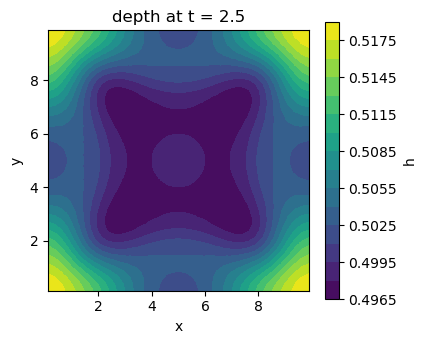

In [4]:
import matplotlib.pyplot as plt

n = mesh.n_inner_cells
x, y = np.asarray(mesh.cell_centers)[:2, :n]
fig, ax = plt.subplots(figsize=(4.2, 3.6))
cs = ax.tricontourf(x, y, h_jax, levels=20)
fig.colorbar(cs, ax=ax, label="h")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("depth at t = 2.5")
plt.show()

In [5]:
assert np.abs(h_jax - h_numpy).max() < 1e-8, "NumPy and JAX disagree"